# Chapter 32: Electrical circuits

The code for this chapter from [*Matrices in Practice*](https://trgoodale.github.io/matrix-book/part-6/32-circuits.html), by Tom Goodale.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/trgoodale/matrix-book/blob/main/code/python/32-circuits.ipynb)

Run the cells in order, from the top: later cells use variables set in earlier ones. Change the numbers and run them again to see what happens. The code needs NumPy, SciPy and Matplotlib (and pandas in a few chapters), all of which Colab already has.

Code licensed under the [MIT licence](https://trgoodale.github.io/matrix-book/LICENSE.md).

### Code for Figure 32.1

This draws [Figure 32.1](https://trgoodale.github.io/matrix-book/part-6/32-circuits.html#fig-filter) in the chapter. You don't need it for the rest of the notebook.

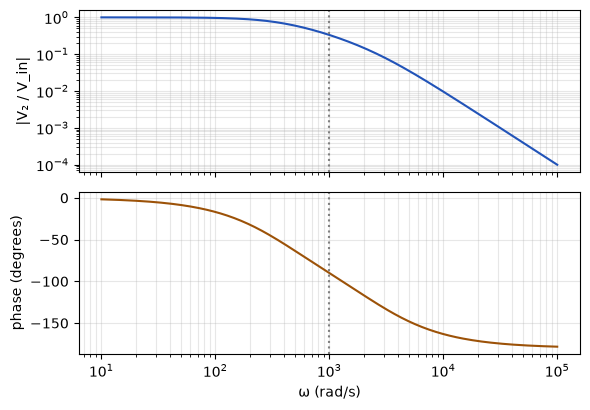

In [1]:
import numpy as np
import matplotlib.pyplot as plt

R, C = 1e3, 1e-6
omegas = np.logspace(1, 5, 200)
V2 = []
for w in omegas:
    Y = np.array([[2 / R + 1j * w * C, -1 / R], [-1 / R, 1 / R + 1j * w * C]])
    V2.append(np.linalg.solve(Y, [1 / R, 0])[1])
V2 = np.array(V2)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4.2), sharex=True)
ax1.loglog(omegas, abs(V2), color="#2153b8")
ax1.set_ylabel("|V₂ / V_in|")
ax2.semilogx(omegas, np.degrees(np.angle(V2)), color="#9c5208")
ax2.set_ylabel("phase (degrees)")
ax2.set_xlabel("ω (rad/s)")
for ax in (ax1, ax2):
    ax.axvline(1000, color="0.5", ls=":")
    ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## In code

In [2]:
import numpy as np

# Example 1: nodal analysis
G = np.array([[0.3, -0.2, 0], [-0.2, 0.5, -0.2], [0, -0.2, 0.3]])
v = np.linalg.solve(G, [3, 0, 0])
print(v)

# Example 2: modified nodal analysis with a 12 V source at node 1
M = np.zeros((4, 4))
M[:3, :3] = G
M[0, 3] = M[3, 0] = 1
print(np.linalg.solve(M, [0, 0, 0, 12]))       # V1, V2, V3, Is

# Example 3: a complex system for the AC filter
R, C, w = 1e3, 1e-6, 1000
Y = np.array([[2 / R + 1j * w * C, -1 / R], [-1 / R, 1 / R + 1j * w * C]])
V = np.linalg.solve(Y, [1 / R, 0])
print(V)
print(np.abs(V), np.degrees(np.angle(V)))      # amplitudes and phases

[15.71428571  8.57142857  5.71428571]
[12.          6.54545455  4.36363636 -2.29090909]
[3.33333333e-01-0.33333333j 6.60813996e-19-0.33333333j]
[0.47140452 0.33333333] [-45. -90.]


## Exercises

The code exercises from the [end of the chapter](https://trgoodale.github.io/matrix-book/part-6/32-circuits.html#sec-circuits-exercises). Worked solutions are in the notebook `solutions-part-6.ipynb`, and in the [book's solutions](https://trgoodale.github.io/matrix-book/appendices/solutions-6.html#sec-solutions-circuits).

### Exercise 6

For the filter of Example 3, find the angular frequency at which $\lvert V_2/V_{\text{in}}\rvert = 1/\sqrt{2}$, by solving the complex system at many frequencies or with a root finder.

In [3]:
# Your code here